# Benchmarks: clobe

*The R package clobe 0.8.0 against its port `psp.clobe`, on the same machine and the same inputs.*

clobe's functions are written in C++ (Rcpp and RcppArmadillo) and called from R once per result, pattern set or enumeration; `brutes()` runs on every core with RcppParallel. The port does the same work as tensor operations: on whole batches of results at once, on the CPU or on the GPU. This notebook measures what that buys and what it costs, function by function, and checks that both give the same answers.

The workloads and how they are measured are described in [../benchmarks/clobe/README.md](../benchmarks/clobe/README.md). In short: every call is timed as a user would make it, from inputs already in memory (on the GPU, already on the device) to the result, and each figure is the median of up to five samples after a warm-up call. Everything is float64. The checksum of each result (a sum of the cells, a count or the g-distance) is computed in the timed call on both sides.

In [1]:
import platform
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from figure_style import figures, titled

show = figures("benchmarks-clobe")

grey, muted = "#6c757d", "#6c757d"
R = "clobe 0.8.0 (R)"
builds = {"psp-torch cpu float64": "#eb6834", "psp-torch cuda float64": "#1baf7a"}
short = {"psp-torch cpu float64": "torch CPU", "psp-torch cuda float64": "torch GPU"}


def duration(s):
    if s >= 1:
        return f"{s:,.2f} s"
    if s >= 1e-3:
        return f"{1e3 * s:,.2f} ms"
    return f"{1e6 * s:,.1f} µs"


def times(v):
    return f"{v:,.0f}×" if v >= 10 else f"{v:.2g}×"


results = Path("../benchmarks/clobe/results")
runs = pd.concat([pd.read_csv(results / "r.csv"), pd.read_csv(results / "torch.csv")])
runs["size"] = runs["size"].astype(int)
order = list(dict.fromkeys(runs["function"]))
seconds = runs.pivot_table(index=["function", "size"], columns="build", values="seconds")
seconds = seconds.reindex(sorted(seconds.index, key=lambda i: (order.index(i[0]), i[1])))
check = runs.pivot_table(index=["function", "size"], columns="build", values="check")
cpu_name = subprocess.run(["sh", "-c", "lscpu | sed -n 's/^Model name: *//p'"],
                          capture_output=True, text=True).stdout.strip() or platform.processor()
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU"
display(Markdown(f"Measured on one machine: {cpu_name} and {gpu_name}. The R package's `brutes()` "
                 f"runs on every hardware thread; torch {torch.__version__} uses "
                 f"{torch.get_num_threads()} CPU threads."))


Measured on one machine: AMD Ryzen 7 5800X 8-Core Processor and NVIDIA GeForce RTX 3060. The R package's `brutes()` runs on every hardware thread; torch 2.11.0+cu128 uses 8 CPU threads.

## Same answers

For every workload, the checksum of the port's result against the R package's. Counts and sums of cells must be equal; g-distances may differ in the last bits, because the GPU adds the frequencies in a different order.

In [2]:
agree = pd.DataFrame(index=check.index)
for build in builds:
    torch_check = check[build].dropna()
    exact = np.isclose(torch_check, check.loc[torch_check.index, R], rtol=1e-12, atol=0)
    agree[short[build]] = pd.Series(np.where(exact, "same", "DIFFERENT"), index=torch_check.index)
agree["R checksum"] = check[R].map(lambda v: f"{v:.15g}")
agree = agree.fillna("not run")
display(Markdown(f"**{(agree == 'same').sum().sum()} of {(agree[[short[b] for b in builds]] != 'not run').sum().sum()}** "
                 "port results agree with the R package."))
agree

**39 of 39** port results agree with the R package.

torch CPU torch GPU         R checksum
function              size                                         
brutes                5           same      same               2131
                      6           same      same              28623
                      7           same      same             437179
                      8           same      same            7185783
gdistance             1000        same      same  0.686136660715578
                      10000       same      same  0.554236849027623
                      38703       same      same  0.707106781186548
imac (every row)      1000        same      same                345
                      10000       same      same                302
                      100000      same      same               3225
imac (one vector)     1           same   not run                 -9
orderings (semiorder) 5           same   not run               2371
                      6           same   not run              38703
                      7           same   not run             763099
orderings (weak)      7           same   not run              47293
                      8           same   not run             545835
                      9           same   not run            7087261
pattern_distance      100         same      same             128906
                      1000        same      same           13071772
                      5000        same      same          329275610
patterns              1000        same      same                554
                      10000       same      same               1557
                      100000      same      same               2187

## Speed

Seconds per call, and how many times faster the port is than the R package (above 1×, the port is faster; below 1×, R is).

In [3]:
speedup = pd.DataFrame({b: seconds[R] / seconds[b] for b in builds})
table = pd.DataFrame({"R": seconds[R].map(duration)})
for b in builds:
    table[short[b]] = seconds[b].map(lambda s: duration(s) if pd.notna(s) else "")
    table[f"{short[b]} vs R"] = speedup[b].map(lambda v: times(v) if pd.notna(v) else "")
table

R  torch CPU torch CPU vs R  torch GPU  \
function              size                                                     
imac (one vector)     1          3.4 µs    42.4 µs         0.081×              
imac (every row)      1000      3.85 ms   181.8 µs            21×   179.7 µs   
                      10000    39.00 ms    1.40 ms            28×   200.9 µs   
                      100000  420.00 ms   22.72 ms            18×    1.09 ms   
patterns              1000     10.40 ms   420.0 µs            25×   612.3 µs   
                      10000    91.00 ms    2.16 ms            42×   658.7 µs   
                      100000  962.00 ms   26.80 ms            36×    1.94 ms   
gdistance             1000      1.08 ms   489.6 µs           2.2×    1.04 ms   
                      10000    10.60 ms    2.28 ms           4.7×    1.31 ms   
                      38703    31.00 ms    3.12 ms           9.9×    1.51 ms   
pattern_distance      100      109.9 µs   140.9 µs          0.78×   476.0 µs   
                      1000     11.80 ms   859.7 µs            14×   576.5 µs   
                      5000    404.00 ms   64.60 ms           6.3×    4.25 ms   
orderings (semiorder) 5        300.0 µs   953.2 µs          0.31×              
                      6        10.50 ms   12.86 ms          0.82×              
                      7       501.00 ms  252.53 ms             2×              
orderings (weak)      7        12.25 ms    6.42 ms           1.9×              
                      8       350.00 ms  126.04 ms           2.8×              
                      9          5.35 s     3.76 s           1.4×              
brutes                5        730.8 µs    1.23 ms          0.59×    1.46 ms   
                      6        13.00 ms   43.04 ms           0.3×    2.93 ms   
                      7       251.00 ms  568.23 ms          0.44×   23.51 ms   
                      8          1.53 s     6.94 s          0.22×  269.14 ms   

                             torch GPU vs R  
function              size                   
imac (one vector)     1                      
imac (every row)      1000              21×  
                      10000            194×  
                      100000           386×  
patterns              1000              17×  
                      10000            138×  
                      100000           496×  
gdistance             1000               1×  
                      10000            8.1×  
                      38703             21×  
pattern_distance      100             0.23×  
                      1000              20×  
                      5000              95×  
orderings (semiorder) 5                      
                      6                      
                      7                      
orderings (weak)      7                      
                      8                      
                      9                      
brutes                5                0.5×  
                      6                4.4×  
                      7                 11×  
                      8                5.7×

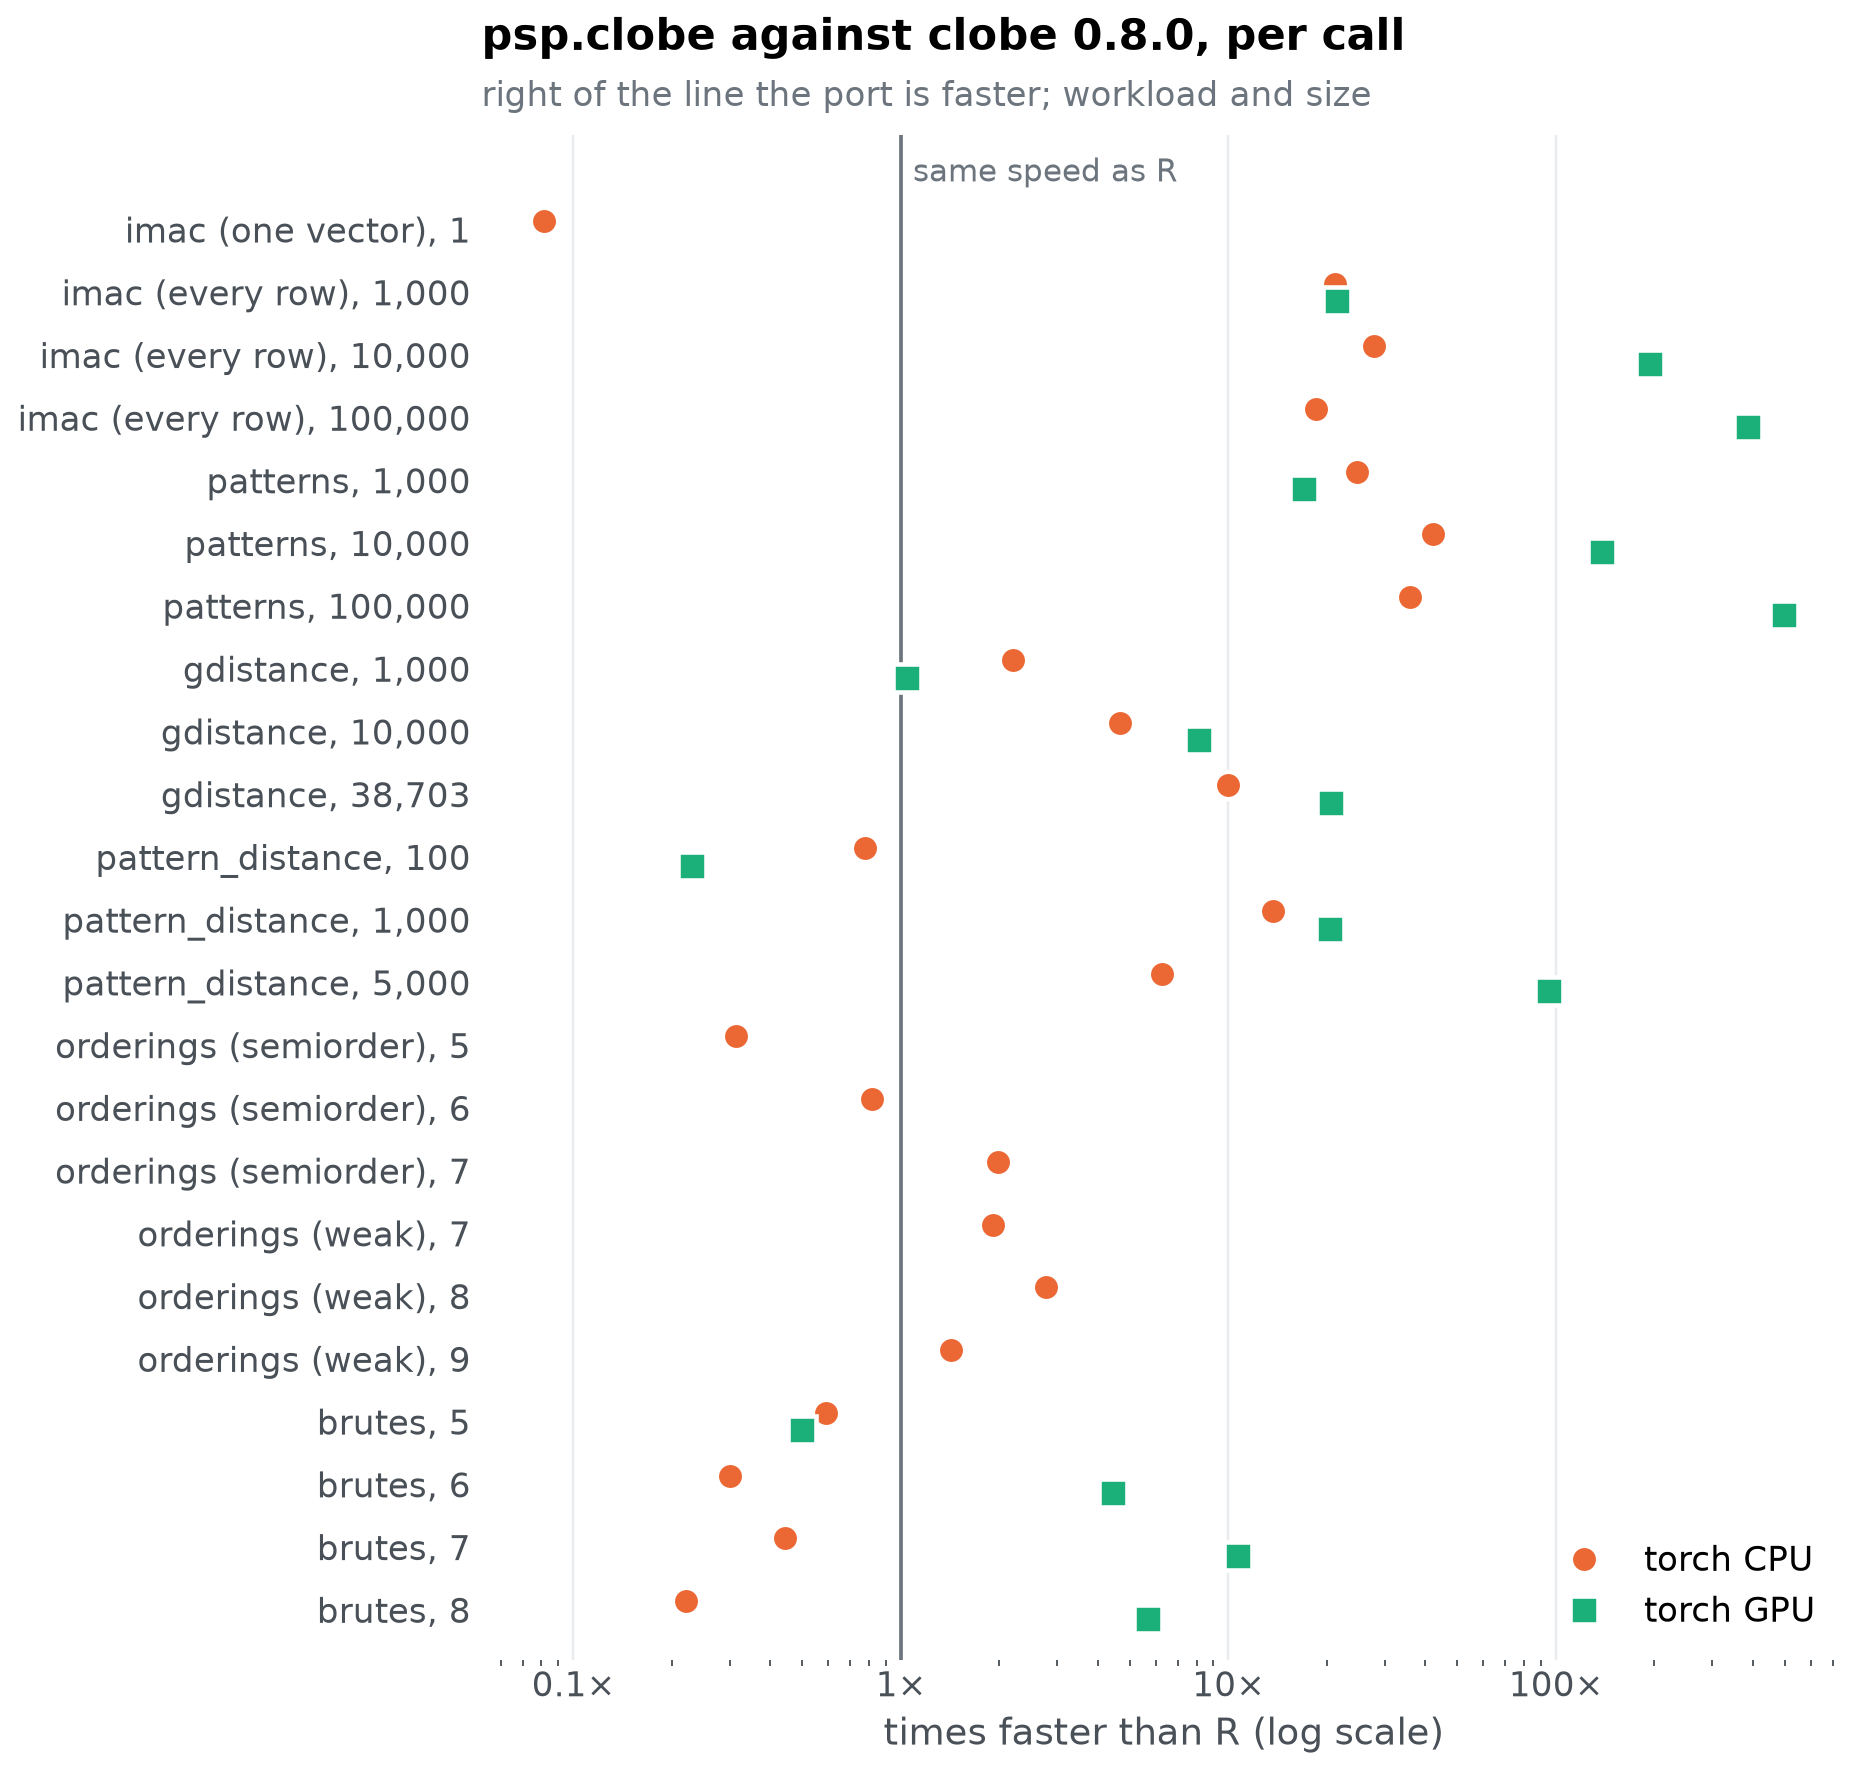

In [4]:
labels = [f"{f}, {s:,}" for f, s in speedup.index]
y = np.arange(len(labels))[::-1]
fig, ax = plt.subplots(figsize=(8, 9))
ax.axvline(1, color=grey, linewidth=1.2)
ax.annotate("same speed as R", xy=(1, y.max() + 0.9), xytext=(4, 0), textcoords="offset points",
            color=muted, fontsize=10, va="center")
for b, colour in builds.items():
    marker = "o" if "cpu" in b else "s"
    ax.plot(speedup[b], y + (0.14 if "cpu" in b else -0.14), marker, color=colour, markersize=9, markeredgecolor="white",
            markeredgewidth=1.5, linestyle="none", label=short[b])
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}×")
ax.set_yticks(y, labels)
ax.set_ylim(-0.8, y.max() + 1.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("times faster than R (log scale)")
ax.legend(loc="lower right")
titled(ax, "psp.clobe against clobe 0.8.0, per call",
       "right of the line the port is faster; workload and size")
show(fig, "speed-against-r")

## What the numbers show

In [5]:
cpu, gpu = "psp-torch cpu float64", "psp-torch cuda float64"


def s(function, size, build):
    return seconds.loc[(function, size), build]


def x(function, size, build):
    return speedup.loc[(function, size), build]


display(Markdown(f'''
**One result at a time is the R package's ground.** `imac()` on a single result takes {duration(s("imac (one vector)", 1, R))} in R and {duration(s("imac (one vector)", 1, cpu))} in the port: every tensor operation costs a few microseconds of dispatch, whatever its size, and building one small matrix takes a handful of them. In a loop over results, as R has to run it, the port would be the slower of the two.

**Batches are the port's ground.** Given all the results at once, `imac()` builds 100,000 matrices in {duration(s("imac (every row)", 100000, cpu))} on the CPU, {times(x("imac (every row)", 100000, cpu))} faster than R's {duration(s("imac (every row)", 100000, R))} for one call per result. `patterns()` adds finding the distinct patterns, which the port does by packing each pattern into one integer and sorting those, where R pastes every pattern into a string: {times(x("patterns", 1000, cpu))} to {times(x("patterns", 100000, cpu))} faster on the CPU. This is also what makes `imac()` a cheap `discretize` for `psp.PSP`, which hands it a whole batch per iteration.

**g-distance and pattern distances** are one call each in both packages. `gdistance()` is {times(x("gdistance", 1000, cpu))} to {times(x("gdistance", 38703, cpu))} faster on the CPU: R compares every human pattern with every model pattern, the port packs the patterns into integers and matches them by sorting. `pattern_distance()` between every pair of 5,000 patterns, 25 million distances, takes {duration(s("pattern_distance", 5000, R))} in R, {duration(s("pattern_distance", 5000, cpu))} on the CPU (in float32, which is exact for integer codes) and {duration(s("pattern_distance", 5000, gpu))} on the GPU, where the distances between patterns of -1, 0 and 1 are computed as matrix products. For the smallest workloads the GPU is no faster than the CPU: a kernel launch costs more than the work.

**Enumerations.** `orderings()` is at its slowest relative to R for few stimuli, where the fixed cost of the tensor operations dominates ({times(x("orderings (semiorder)", 5, cpu))} for the 2,371 semiorders of 5 stimuli, in about a millisecond), and faster for many ({times(x("orderings (semiorder)", 7, cpu))} for the 763,099 semiorders of 7, {times(x("orderings (weak)", 9, cpu))} for the 7 million weak orderings of 9). The port also keeps the matrices as int8, an eighth of the memory of R's doubles, so it can list the 17.6 million semiorders of 8 stimuli (1.1 GB), which in R would take some 18 GB.

**`brutes()`** is where R's multithreaded C++ is strongest. It streams through the assignments on every hardware thread, while the port builds each block of assignments as tensors and sorts their keys: on the CPU the port is {times(1 / x("brutes", 7, cpu))} slower for 11 values and 7 stimuli and {times(1 / x("brutes", 8, cpu))} slower for 8 (214 million assignments, {duration(s("brutes", 8, cpu))} against {duration(s("brutes", 8, R))}). On the GPU the same work takes {duration(s("brutes", 8, gpu))}, {times(x("brutes", 8, gpu))} faster than R.
'''))


**One result at a time is the R package's ground.** `imac()` on a single result takes 3.4 µs in R and 42.4 µs in the port: every tensor operation costs a few microseconds of dispatch, whatever its size, and building one small matrix takes a handful of them. In a loop over results, as R has to run it, the port would be the slower of the two.

**Batches are the port's ground.** Given all the results at once, `imac()` builds 100,000 matrices in 22.72 ms on the CPU, 18× faster than R's 420.00 ms for one call per result. `patterns()` adds finding the distinct patterns, which the port does by packing each pattern into one integer and sorting those, where R pastes every pattern into a string: 25× to 36× faster on the CPU. This is also what makes `imac()` a cheap `discretize` for `psp.PSP`, which hands it a whole batch per iteration.

**g-distance and pattern distances** are one call each in both packages. `gdistance()` is 2.2× to 9.9× faster on the CPU: R compares every human pattern with every model pattern, the port packs the patterns into integers and matches them by sorting. `pattern_distance()` between every pair of 5,000 patterns, 25 million distances, takes 404.00 ms in R, 64.60 ms on the CPU (in float32, which is exact for integer codes) and 4.25 ms on the GPU, where the distances between patterns of -1, 0 and 1 are computed as matrix products. For the smallest workloads the GPU is no faster than the CPU: a kernel launch costs more than the work.

**Enumerations.** `orderings()` is at its slowest relative to R for few stimuli, where the fixed cost of the tensor operations dominates (0.31× for the 2,371 semiorders of 5 stimuli, in about a millisecond), and faster for many (2× for the 763,099 semiorders of 7, 1.4× for the 7 million weak orderings of 9). The port also keeps the matrices as int8, an eighth of the memory of R's doubles, so it can list the 17.6 million semiorders of 8 stimuli (1.1 GB), which in R would take some 18 GB.

**`brutes()`** is where R's multithreaded C++ is strongest. It streams through the assignments on every hardware thread, while the port builds each block of assignments as tensors and sorts their keys: on the CPU the port is 2.3× slower for 11 values and 7 stimuli and 4.5× slower for 8 (214 million assignments, 6.94 s against 1.53 s). On the GPU the same work takes 269.14 ms, 5.7× faster than R.


## In short

Use the port's functions on batches: `imac()` on all results at once, `patterns()` and `gdistance()` on whole sets, and `brutes()` on the GPU when there is one. The R package is faster for one small call at a time, and its `brutes()` is faster on a CPU.